# Comparación de resultados

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C, comparar as K
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
panel = C.load_panel()
t = K.tabla(panel); t.to_csv("results/tabla_comparativa.csv", index=False)
pd.set_option("display.width", 220, "display.max_columns", 30)
display(t.round(4))

,modelo,familia,L (h),multi-paso,covariables,params totales,params entrenables,t_entrenamiento (s),t_inferencia (s),hardware,MAE,RMSE,WAPE,MASE,MASE 22-28 dic,pinball,cobertura P10-P90
0,lightgbm_global,Árboles,1-24 y 168 (rezagos),directa global (h como feature),sí (calendario),126000.0,126000.0,188.5,3.1,Apple M5,33.9263,164.6167,0.0629,0.8499,1.5421,None,None
1,mlp,MLP,336.0,multi-salida,sí,533528.0,533528.0,177.2,4.5,Apple M5 (GPU MPS),37.4969,175.6836,0.0695,0.8927,1.6360,None,None
2,dlinear,Lineal,336.0,multi-salida,no,16176.0,16176.0,26.4,2.3,Apple M5 (GPU MPS),37.5763,184.7384,0.0697,0.9165,2.0230,None,None
3,nlinear,Lineal,336.0,multi-salida,no,8088.0,8088.0,15.0,2.1,Apple M5 (GPU MPS),37.6243,184.6919,0.0698,0.9280,1.9949,None,None
4,mstl,Baseline,1344.0,"local, reajuste por origen",no,0.0,0.0,1245.3,1245.3,Apple M5,38.8977,193.0826,0.0721,0.9521,2.1792,None,None
5,snaive_24h,Baseline,1344.0,"local, reajuste por origen",no,0.0,0.0,0.9,0.9,Apple M5,45.8698,236.3032,0.0850,1.0875,2.4717,None,None
6,snaive_168h,Baseline,1344.0,"local, reajuste por origen",no,0.0,0.0,0.9,0.9,Apple M5,43.1660,192.4684,0.0800,1.1494,1.6672,None,None
7,naive,Baseline,1344.0,"local, reajuste por origen",no,0.0,0.0,0.9,0.9,Apple M5,174.4063,531.8018,0.3234,4.2734,4.3498,None,None


**Notas de la tabla.** MAE/RMSE en kWh y WAPE/MASE sobre los 92 orígenes de prueba (H = 24, 100 clientes). El MASE escala cada cliente con el MAE in-sample del seasonal naive de 24 h en entrenamiento. *MASE con H = 168* no aplica: todos los modelos pronostican H = 24 y el protocolo de backtest es de 24 h. En los modelos locales de StatsForecast el ajuste ocurre dentro de `predict` en cada origen, por lo que su tiempo de ajuste se contabiliza como tiempo de entrenamiento (columna `t_entrenamiento`). Los tiempos de PyTorch son de la GPU de la Mac (MPS), los de LightGBM y StatsForecast de CPU: no son comparables en estricto sentido.

In [2]:
best = t.iloc[0]; sn = t[t.modelo == "snaive_24h"].iloc[0]
print(f"Mejor modelo: {best.modelo} (MASE {best.MASE:.3f}); frente al seasonal naive 24 h (MASE {sn.MASE:.3f}): "
      f"{1 - best.MASE / sn.MASE:.1%} menos MASE, {1 - best.MAE / sn.MAE:.1%} menos MAE, {1 - best.WAPE / sn.WAPE:.1%} menos WAPE.")

Mejor modelo: lightgbm_global (MASE 0.850); frente al seasonal naive 24 h (MASE 1.088): 21.8% menos MASE, 26.0% menos MAE, 26.0% menos WAPE.


## Gráfica 1 – MASE de prueba contra tiempo de entrenamiento (frontera de Pareto)

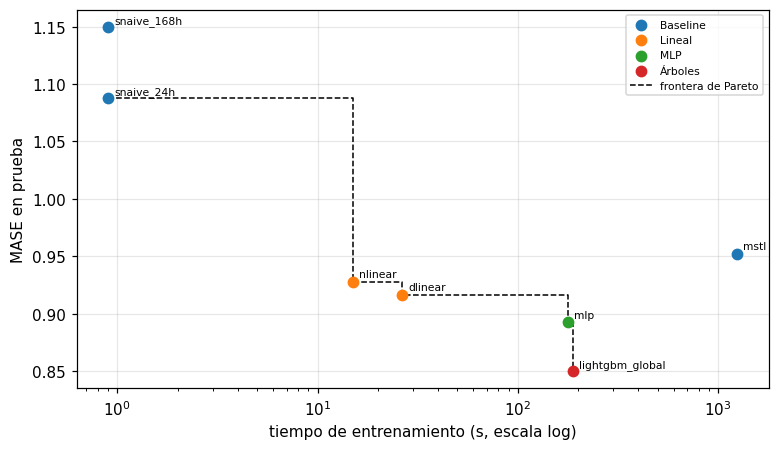

Frontera de Pareto: ['snaive_24h', 'nlinear', 'dlinear', 'mlp', 'lightgbm_global']
Fuera de la gráfica: naive, MASE 4.27


In [3]:
x = t["t_entrenamiento (s)"].clip(lower=0.1).to_numpy(); y = t["MASE"].to_numpy()
mask = t.modelo != "naive"                       # el naive (MASE 4.3) distorsiona el eje y; se indica en el pie
fr = K.pareto_front(x[mask], y[mask]); xs, ys = x[mask][fr], y[mask][fr]
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for fam, g in t[mask].groupby("familia"):
    ax.scatter(g["t_entrenamiento (s)"].clip(lower=.1), g.MASE, s=45, label=fam, zorder=3)
for _, r in t[mask].iterrows(): ax.annotate(r.modelo, (max(r["t_entrenamiento (s)"], .1), r.MASE), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.step(xs, ys, where="post", c="k", lw=1, ls="--", label="frontera de Pareto", zorder=2)
ax.set_xscale("log"); ax.set_xlabel("tiempo de entrenamiento (s, escala log)"); ax.set_ylabel("MASE en prueba"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figs/pareto_mase_tiempo.png"); plt.show()
print("Frontera de Pareto:", list(t[mask].modelo.iloc[fr])); print("Fuera de la gráfica: naive, MASE", round(float(t.loc[~mask, "MASE"].iloc[0]), 2))

## Gráfica 2 – MAE por paso del horizonte (h = 1,…,24), una curva por modelo

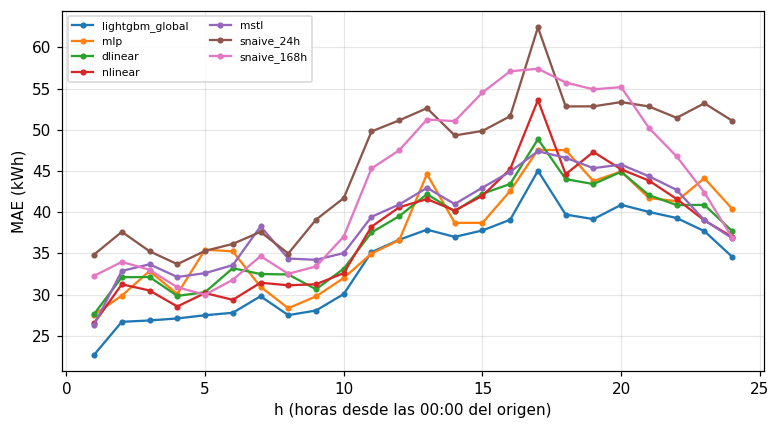

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4))
for m in t.modelo:
    if m == "naive": continue
    bh = C.evaluate(C.PRED_DIR / f"{m}.parquet", panel)["by_h"]
    ax.plot(bh.index, bh["MAE"], "o-", ms=3, label=m)
ax.set_xlabel("h (horas desde las 00:00 del origen)"); ax.set_ylabel("MAE (kWh)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("figs/mae_por_horizonte.png"); plt.show()

## Gráfica 3 – MASE contra meses de historia de entrenamiento
Seasonal naive (no entrena: línea horizontal), LightGBM, DLinear y, cuando existan, el mejor recurrente y PatchTST; Chronos zero-shot como línea de referencia. Se añaden MLP y NLinear. 33 meses = toda la historia hasta 2014-09-30.

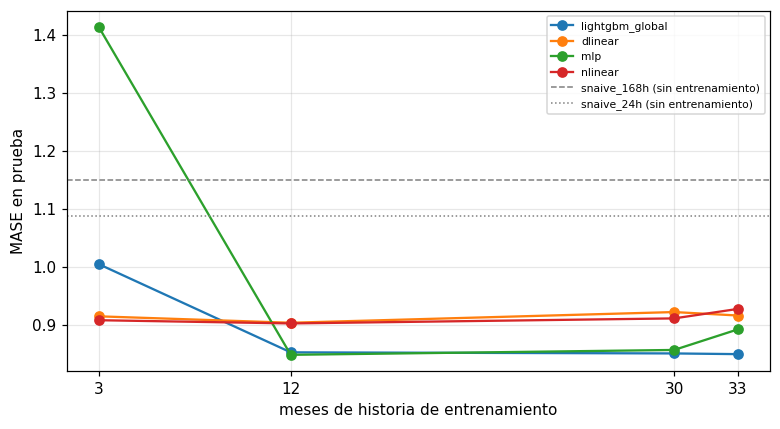

In [5]:
def hist_curve(fam):
    pts = []
    for months, tag in [(3, "_hist03m"), (12, "_hist12m"), (30, "_hist30m"), (33, "")]:
        p = C.PRED_DIR / f"{fam}{tag}.parquet"
        if p.exists(): pts.append((months, C.evaluate(p, panel)["global"]["MASE"]))
    return pts
fig, ax = plt.subplots(figsize=(7.2, 4))
for fam in K.HISTORIA_MODELOS + ["mlp", "nlinear"]:
    pts = hist_curve(fam)
    if len(pts) > 1: ax.plot(*zip(*pts), "o-", label=fam)
for ref, ls in [("snaive_168h", "--"), ("snaive_24h", ":"), (K.CHRONOS, "-.")]:
    p = C.PRED_DIR / f"{ref}.parquet"
    if p.exists(): ax.axhline(C.evaluate(p, panel)["global"]["MASE"], c="gray", ls=ls, lw=1, label=f"{ref} (sin entrenamiento)")
ax.set_xlabel("meses de historia de entrenamiento"); ax.set_ylabel("MASE en prueba"); ax.legend(fontsize=7); ax.set_xticks([3, 12, 30, 33])
plt.tight_layout(); plt.savefig("figs/mase_vs_historia.png"); plt.show()

## Resultados probabilísticos (DeepAR u otros modelos con cuantiles)

In [6]:
pr = t.dropna(subset=["pinball"])
display(pr[["modelo", "pinball", "cobertura P10-P90"]].round(4) if len(pr) else "Todavía no hay modelos probabilísticos en results/preds (esperando a B). Cobertura esperada del intervalo P10–P90: 80 %.")

'Todavía no hay modelos probabilísticos en results/preds (esperando a B). Cobertura esperada del intervalo P10–P90: 80 %.'

**Estado.** Esta versión incluye solo los modelos de A (baselines, LightGBM, MLP, DLinear, NLinear). Al integrar los de B (LSTM/GRU, seq2seq, N-HiTS/TCN, PatchTST, TFT/iTransformer, DeepAR, Chronos) hay que re-ejecutar el notebook y revisar que el análisis de la sección 8 hable de la tabla final.